In [12]:
import numpy as np
import matplotlib.pyplot as plt
import cvxpy as cp
from functions import AlgPenDisc
from functions import AlgMePa
from functions import AlgRemez
from functions import AlgBF

In [13]:
#X,Y must be a box
Y=[(0,1)]
n=100
X=[(-10,10) for i in range(n)]
X=np.append(X,[(0,100)],axis=0)

def fcp(x):
    return x[-1]

def f(x):
    return np.sin(6*x)+np.log(x+1)
    
def gcp(x,y):
    return cp.abs(cp.sum([x[i]*y**i for i in range(n)])-f(y))-x[-1]


def g(x,y):
    return np.abs(np.sum([x[i]*y**i for i in range(n)])-f(y))-x[-1]

def poly(d,coeff,x):
    return np.sum([coeff[i]*x**i for i in range(d)])

In [14]:
y0=np.array([0])
x0=np.zeros(n+1)
res1=AlgPenDisc(x0,y0,fcp,gcp,g,X,Y,rho=1)

Time 22.90631866455078
Time upper problem 16.877696990966797
Time lower problem 6.023474931716919
Feasibility 3.459198016919629e-07
Final rho 1.5
Rho increases 1
Optimal value 0.013544587113469229
Value function call 29


In [15]:
res1=AlgPenDisc(x0,y0,fcp,gcp,g,X,Y,drop_cuts=True,rho=1)

Time 20.974475145339966
Time upper problem 14.824076414108276
Time lower problem 6.035651683807373
Feasibility 8.966251895635435e-08
Final rho 1.5
Rho increases 1
Optimal value 0.013544587944898821
Value function call 28


In [16]:
res2=AlgMePa(x0,y0,fcp,gcp,g,X,Y,Ub=1)

Time 64.60479044914246
Time upper problem 57.03859281539917
Time lower problem 7.566197633743286
Feasibility -7.566537913936133e-07
Optimal value 0.013544587287510101
Optimality cuts 2
Feasibility cuts 54
Value function calls 56


In [17]:
res3=AlgBF(x0,y0,fcp,gcp,g,X,Y)

Time 22.392860412597656
Time upper problem 16.291621923446655
Time lower problem 6.101238489151001
Feasibility 9.498795212198319e-08
Optimal value 0.013544587605757212
Value function call 25


In [18]:
res3=AlgBF(x0,y0,fcp,gcp,g,X,Y,drop_cuts=True)

Time 19.579288005828857
Time upper problem 13.487999200820923
Time lower problem 6.01228928565979
Feasibility 1.0622847678581904e-07
Optimal value 0.013544589227936672
Value function call 25


In [8]:
res4=AlgRemez(x0,y0,fcp,gcp,g,X,Y)

Time 41.23935389518738
Time upper problem 40.146873474121094
Time lower problem 1.0904779434204102
Feasibility 2.7674737475558153e-05
Optimal value 0.48998235839777177
Value function call 99


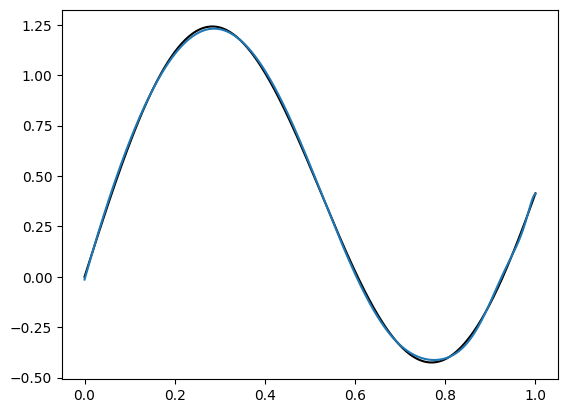

In [71]:
N = 400
x = np.linspace(Y[0][0], Y[0][1], N)


fig, ax = plt.subplots()
ax.plot(x, f(x), "k")
poly1=[poly(n,res1[0],xi) for xi in x]
ax.plot(x, poly1)

#ax.set(aspect=1)